# Count Data and Poisson Models

## Count Data
- One of the motivations for logistic regression was that linear regression might deliver values outside $[0,1]$; i.e. not probabilities
- A similar problem comes up with data that have discrete values, like $\{0, 1, 2, ... \}$; we call this **count data**
- If you are talking about millions of pounds of fish, you can fudge the discreteness of the data, but if you are talking about predicting the number of goals scored or children per family or cancerous lymph nodes, you might not
- How do we repurpose MLE for estimating the mass functions of count-value random variables?

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import statsmodels.api as sm
from scipy.stats import poisson

df = pd.read_parquet("./data/GSS.parquet", engine="pyarrow")
print(df.shape)
df.head()

(75699, 20)


,year,id_,wrkstat,marital,spwrksta,sibs,childs,age,educ,speduc,degree,padeg,madeg,spdeg,sex,income,rincome,hapmar,realinc,ballot
0,1972,1,Working full time,Never married,.i: Inapplicable,3,0,23,4 years of college,.i: Inapplicable,Bachelor's,Less than high school,.i: Inapplicable,.i: Inapplicable,FEMALE,.i: Inapplicable,.i: Inapplicable,.i: Inapplicable,18951.0,.i: Inapplicable
1,1972,2,Retired,Married,KEEPING HOUSE,4,5,70,10th grade,12th grade,Less than high school,Less than high school,Less than high school,High school,MALE,.i: Inapplicable,.i: Inapplicable,.i: Inapplicable,24366.0,.i: Inapplicable
2,1972,3,Working part time,Married,WORKING FULLTIME,5,4,48,12th grade,11th grade,High school,Less than high school,Less than high school,.n: No answer,FEMALE,.i: Inapplicable,.i: Inapplicable,.i: Inapplicable,24366.0,.i: Inapplicable
3,1972,4,Working full time,Married,WORKING FULLTIME,5,0,27,5 years of college,8 or more years of college,Bachelor's,Bachelor's,High school,Graduate,FEMALE,.i: Inapplicable,.i: Inapplicable,.i: Inapplicable,30458.0,.i: Inapplicable
4,1972,5,Keeping house,Married,TEMP NOT WORKING,2,2,61,12th grade,12th grade,High school,Less than high school,Less than high school,High school,FEMALE,.i: Inapplicable,.i: Inapplicable,.i: Inapplicable,50763.0,.i: Inapplicable


## The General Social Survey

- The GSS is a nationally representative panel dataset that has been running for decades, and can be used to look at cross-sections of behavior across society along with demographic data
- `childs` records the number of children, with a top category of **8 or more**.
- Age is recorded as **89 or older** at the upper end; use 89 as an approximate predictor for those respondents.

In [6]:
df['childs'] = pd.to_numeric(df['childs'].replace({'8 or more': '8'}), errors='coerce')
df['age'] = pd.to_numeric(df['age'].replace({'89 or older': '89'}), errors='coerce')

y = df['childs'].dropna()
max_kids = int( y.max() )
k_grid = np.arange(max_kids + 1)
count_labels = [str(k) for k in range(max_kids)] + [f"{max_kids}+"]

print(f"Valid counts: {len(y):,}; missing responses: {df['childs'].isna().sum():,}")
print(f"Zero share: {y.eq(0).mean():.3f}; {max_kids}+ share: {y.eq(max_kids).mean():.3f}")
print(f"Mean: {y.mean():.3f}; variance: {y.var():.3f}")

Valid counts: 75,407; missing responses: 292
Zero share: 0.278; 8+ share: 0.014
Mean: 1.909; variance: 3.083


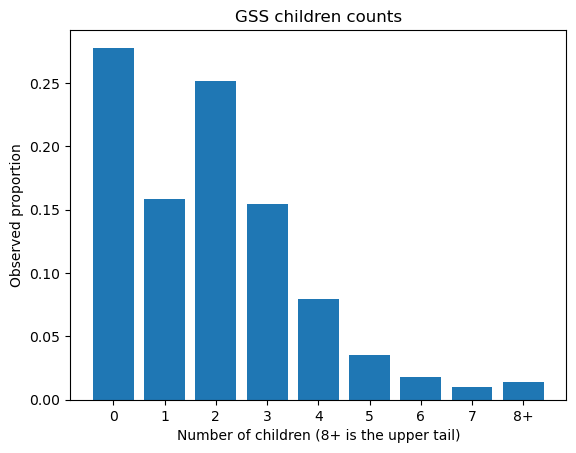

In [7]:
observed = y.value_counts(normalize=True).reindex(k_grid, fill_value=0)
plt.bar(count_labels, observed)
plt.xlabel('Number of children (8+ is the upper tail)')
plt.ylabel('Observed proportion')
plt.title('GSS children counts')
plt.show()

- The normal MLE would say children are normally distributed with a mean of 1.9 and a variance of 3.1
- We would prefer our model deliver a PMF like the one immediately above, with weights on plausible family sizes

# 1. The Likelihood

## The MLE Approach

1. Derive the individual density/probability terms for each observation, as appropriate
2. Multiply the terms together to get the likelihood (the density of the data, given parameters), and take logs to get the log likelihood
3. Maximize over parameters

## (1) Individual Terms: Poisson Mass Function

- The Poisson probability mass function, for each integer $y = 0, 1, 2, ...$
$$
\text{pr}[Y=y,\lambda] = \frac{e^{-\lambda} \lambda^y}{y!} 
$$
- What is the expected value of the process?
$$
\mathbb{E}[Y] = e^{-\lambda} \sum_{y=0}^\infty y \frac{ \lambda^y}{y!} = e^{-\lambda} \lambda \sum_{y=1}^\infty  \frac{ \lambda^{y-1}}{(y-1)!} = e^{-\lambda} \lambda \sum_{x=0}^\infty  \frac{ \lambda^{x}}{x!} = e^{-\lambda} \lambda e^{\lambda} = \lambda
$$
- We only have one parameter here, so we're asking a lot of the Poisson

## (2) (Log-)Likelihood
- Each observation $y_i$ contributes one of the terms:
$$
\mathcal{L}[ y | \lambda ] = \prod_{i=1}^n \frac{e^{-\lambda} \lambda^{y_i} }{y_i!} 
$$
- Taking logs yields the log-likelihood in $\lambda$:
$$
\begin{alignat*}{2}
L(\lambda) &=& \sum_{i=1}^n -\lambda + y_i \log(\lambda) - \log(y_i!) \\
&=&  - n\lambda + \log(\lambda) \sum_{i=1}^n y_i  - \sum_{i=1}^n \log(y_i!) 
\end{alignat*}
$$

## (3) Maximize
- Taking derivatives,
$$
-n + \frac{1}{\hat{\lambda}} \sum_{i=1}^n y_i = 0
$$
and
$$
\hat{\lambda} = \frac{\sum_{i=1}^n y_i}{n}
$$
- The sample mean!

## Prediction and Inference
- Prediction is easy:
$$
\widehat{\text{pr}}[Y=y|\hat{\lambda}] = \frac{e^{-\hat{\lambda}} \hat{\lambda}^y}{y!}, \quad y = 0, 1, 2, ...
$$
- We can always bootstrap the sampling distribution of $\hat{\lambda}$, but the asymptotic CI happens to be
$$
\left( \hat{\lambda} - 1.96 \times \sqrt{\frac{\hat{\lambda}}{n}}, \quad \hat{\lambda} + 1.96 \times \sqrt{\frac{\hat{\lambda}}{n}} \right)
$$


95% CI for λ: [1.90, 1.92]


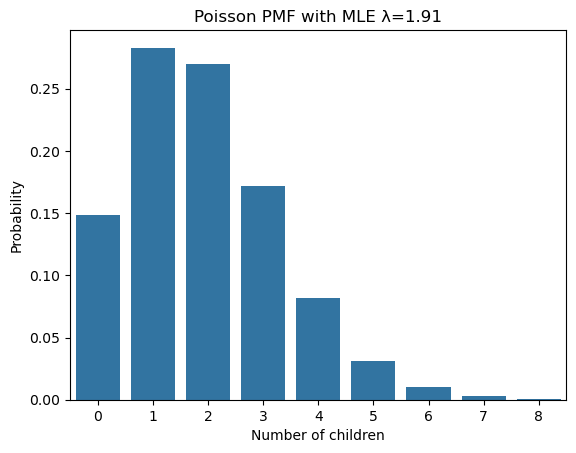

In [8]:
lam = df["childs"].mean()  # Poisson MLE
pmf = poisson.pmf(k_grid, lam)
sns.barplot(x=k_grid, y=pmf).set(title=f'Poisson PMF with MLE λ={lam:.2f}', xlabel='Number of children', ylabel='Probability')

L = lam - 1.96 * np.sqrt(lam / len(y))
U = lam + 1.96 * np.sqrt(lam / len(y))
print(f"95% CI for λ: [{L:.2f}, {U:.2f}]")

## Handling Zero-Inflated Data

- Our prediction lines up with the truth except in a few places:
    1. There are two few zeros
    2. There are too many ones
    3. There are too few 8's
- The first problem is called **zero inflation**, and it's a common problem with fitting count models
- The standard way to solve it is to break the model into two choices: 
    1. Does the family have children? (Bernoulli 0/1)
    2. If so, how many? (Poisson count over 1, 2, 3, ...)
- This is often called a **hurdle model**

## Hurdle Poisson
So we do:

1. Estimate $\hat{p}$ as the proportion of observations with $y>0$
2. The probability of $y|y>0$ is now given by
$$
\mathbb{E}[y|y>0] = \dfrac{\hat{\lambda}}{1-e^{-\hat{\lambda}}}
$$
We can replace the left-hand side of the above equation with the conditional average number of kids, given non-zero kids, and solve for $\hat{\lambda}$

In [11]:
from scipy.optimize import brentq

## 1. Estimate p_hat
positive = y > 0
p_hat = positive.mean()

## 2. Estimate lambda_hat for the positive counts
Ygz = y[y>0].mean()
lam_hat = brentq(lambda l: Ygz - l / (-np.expm1(-l)), 1e-10, Ygz) # Solve numerically for lambda_hat


In [12]:
# 1. Empirical probabilities
empirical = y.value_counts(normalize=True).reindex(k_grid, fill_value=0)

# 2. Vanilla Poisson probabilities
lambda_vanilla = y.mean()
vanilla = poisson.pmf(k_grid, lambda_vanilla)

# 3. Hurdle Poisson probabilities
hurdle = p_hat * poisson.pmf(k_grid, lam_hat) / (1 - np.exp(-lam_hat))
hurdle = np.where(k_grid == 0, 1 - p_hat, hurdle)

# 4. Compare in a table
comparison = pd.DataFrame({
    #"k": k_grid,
    "Empirical": empirical.values,
    "Vanilla Poisson": vanilla,
    "Hurdle Poisson": hurdle
})

display(comparison.round(4))

,Empirical,Vanilla Poisson,Hurdle Poisson
0,0.2779,0.1482,0.2779
1,0.1589,0.2829,0.1722
2,0.2518,0.2701,0.2072
3,0.1548,0.1719,0.1661
4,0.0795,0.0821,0.0999
5,0.0354,0.0313,0.0481
6,0.0183,0.0100,0.0193
7,0.0097,0.0027,0.0066
8,0.0137,0.0006,0.0020


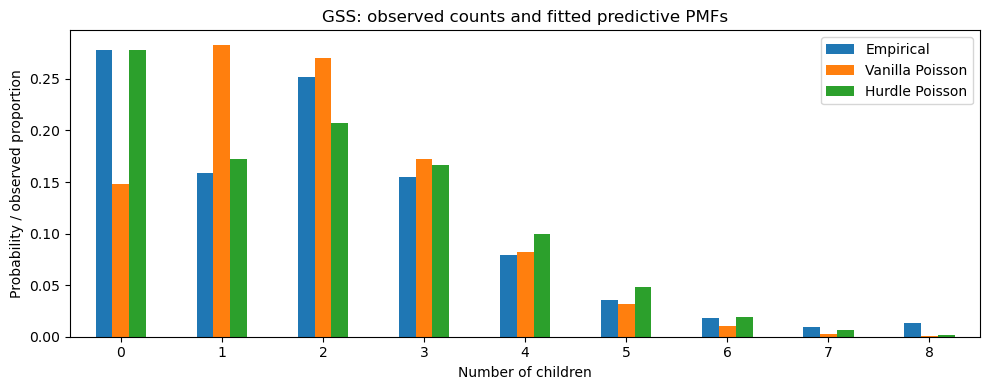

In [27]:
comparison.plot.bar(figsize=(10, 4), rot=0)
plt.xlabel('Number of children')
plt.ylabel('Probability / observed proportion')
plt.title('GSS: observed counts and fitted predictive PMFs')
plt.tight_layout()
plt.show()

# 2. Parameterization

## Add Covariates/Features to the Model

- We know that $\mathbb{E}[Y]=\lambda$, so if we replace $\lambda$ with any function, we are modeling the conditional expectation function
- $\lambda$ must be non-negative, so we tend to get the best results if we set $\lambda_i = \exp( x_i \cdot \beta ) $, so the probability of observing $y_i$ conditional on $x_i$ becomes 
$$
\text{pr}[Y=y_i|X=x_i,\beta] = \frac{e^{- \exp( x_i \cdot \beta)} (\exp(x_i \cdot \beta))^{y_i}}{y_i!} 
$$
- The parameter $\lambda_i = e^{x_i \beta}$ is our $x_i$-conditional expectation of $Y_i$: $\mathbb{E}[Y_i|X=x_i] = e^{x_i \beta}$

## Parameterized MLE

- The the likelihood becomes:
$$
\mathcal{L}[ y| X, \beta] = \prod_{i=1}^n \frac{e^{- \exp( x_i \cdot \beta)} (\exp(x_i \cdot \beta))^{y_i}}{y_i!} 
$$
- And the log-likelihood is:
$$
\begin{alignat*}{2}
L(\beta) &=& \sum_{i=1}^n -\exp(x_i \cdot \beta) + y_i (x_i \cdot \beta) - \log(y_i!) 
\end{alignat*}
$$
- Notice, MSE/SSE/BCE appears nowhere here: It's a truly novel optimization problem

## Gradient Ascent
- The partial derivative of the log-likelihood with respect to $\beta_k$ is:
$$
\dfrac{\partial L(\beta)}{\partial \beta_k } = \sum_{i=1}^n y_i x_{ik} - e^{x_i \cdot \beta} x_{ik}
$$
- Stack these, and you get the gradient vector
- Gradient ascent iterates on
$$
\beta_{t+1} = \beta_t + r \left[ \begin{array}{c} 
\sum_{i=1}^n (y_i  - e^{x_i \cdot \beta_t}) x_{i1}  \\
\sum_{i=1}^n (y_i  - e^{x_i \cdot \beta_t}) x_{i2} \\
\vdots \\
\sum_{i=1}^n (y_i  - e^{x_i \cdot \beta_t}) x_{iK}
\end{array} \right] 
$$
where $r>0$ is the learning rate

## Inference and Prediction
- Bootstrap, StatsModels
- How do we make predictions? For each count value $y=0,1,2...$, we can compute the PMF:
$$
\widehat{\text{pr}}[Y=y|X=x,\hat{\beta}] = \frac{e^{-\exp(x \cdot \hat{\beta})} [\exp(x \cdot \hat{\beta})]^y}{y!}, \quad y = 0, 1, 2, ...
$$

## GSS regression: Adding Covariances

In [16]:
# 1. Select variables
cols = ['childs', 'age', 'sex', 'degree', 'marital']
rdf = df[cols].dropna().copy()

# 2. Clean categorical variables
cats = ['sex', 'degree', 'marital']

for col in cats:
    rdf[col] = rdf[col].replace(r'^\..*', 'Missing', regex=True)

# 3. Set reference categories (first category is omitted)
rdf['sex'] = pd.Categorical(rdf['sex'],
    categories=['FEMALE', 'MALE', 'Missing'])

rdf['degree'] = pd.Categorical(rdf['degree'],
    categories=['High school', 'Less than high school',
                'Associate/junior college', "Bachelor's",
                'Graduate', 'Missing'])

rdf['marital'] = pd.Categorical(rdf['marital'],
    categories=['Married', 'Never married', 'Divorced',
                'Separated', 'Widowed', 'Missing'])

# 4. Outcome and predictors
y_reg = rdf['childs']
X = rdf[['age', 'sex', 'degree', 'marital']]

# 5. Create dummy variables and add intercept
X = pd.get_dummies(X, drop_first=True, dtype=float)
X = sm.add_constant(X)

# 6. Poisson regression
X = X.astype(float)
y_reg = y_reg.astype(float)

model = sm.GLM(y_reg, X, family=sm.families.Poisson()).fit()
print(model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 childs   No. Observations:                74590
Model:                            GLM   Df Residuals:                    74576
Model Family:                 Poisson   Df Model:                           13
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.2344e+05
Date:                Mon, 16 Nov 2026   Deviance:                       99133.
Time:                        23:15:10   Pearson chi2:                 1.00e+05
No. Iterations:                     5   Pseudo R-squ. (CS):             0.3852
Covariance Type:            nonrobust                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

In [18]:
# 1. Probit: probability of having any children
positive = y_reg > 0

probit = sm.Probit(positive.astype(int), X).fit()

# 2. Poisson: number of children, conditional on having any
poisson_pos = sm.GLM(
    y_reg[positive],
    X.loc[positive],
    family=sm.families.Poisson()
).fit()

# 3. Results
print(probit.summary())

Optimization terminated successfully.
         Current function value: 0.425343
         Iterations 6
                          Probit Regression Results                           
Dep. Variable:                 childs   No. Observations:                74590
Model:                         Probit   Df Residuals:                    74576
Method:                           MLE   Df Model:                           13
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2801
Time:                        23:18:52   Log-Likelihood:                -31726.
converged:                       True   LL-Null:                       -44069.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                               0.7059      0.020     35.267  

In [19]:
print(poisson_pos.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 childs   No. Observations:                53873
Model:                            GLM   Df Residuals:                    53859
Model Family:                 Poisson   Df Model:                           13
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -92848.
Date:                Mon, 16 Nov 2026   Deviance:                       37940.
Time:                        23:18:56   Pearson chi2:                 4.10e+04
No. Iterations:                     5   Pseudo R-squ. (CS):            0.08326
Covariance Type:            nonrobust                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

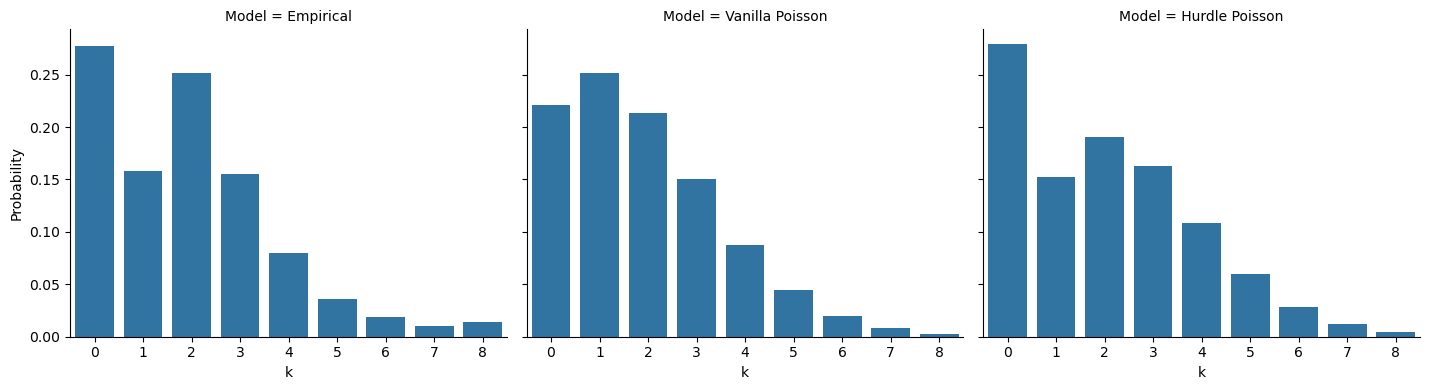

In [20]:
# 1. Predicted parameters for each respondent
lam_vanilla = model.predict(X)
p = probit.predict(X)
lam_positive = poisson_pos.predict(X)

# 2. Grid of child counts
k_grid = np.arange(0, int(y_reg.max()) + 1)

# 3. Empirical probabilities
empirical = y_reg.value_counts(normalize=True).reindex(k_grid, fill_value=0).values

# 4. Average predicted probabilities: vanilla Poisson
vanilla = np.array([
    poisson.pmf(k, lam_vanilla).mean() for k in k_grid
])

# 5. Average predicted probabilities: hurdle model
hurdle = np.array([
    (1 - p).mean() if k == 0
    else (p * poisson.pmf(k, lam_positive) / (1 - np.exp(-lam_positive))).mean()
    for k in k_grid
])

# 6. Plot
comparison = pd.DataFrame({
    'k': k_grid,
    'Empirical': empirical,
    'Vanilla Poisson': vanilla,
    'Hurdle Poisson': hurdle
})

sns.catplot(
    data=comparison.melt('k', var_name='Model', value_name='Probability'),
    x='k', y='Probability', col='Model',
    kind='bar', sharey=True, height=4, aspect=1.2
)

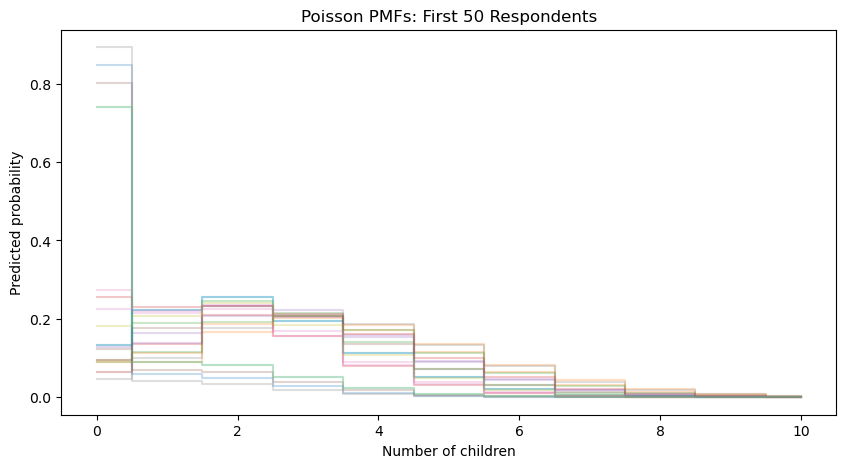

In [23]:
k_grid = np.arange(0, 11)

plt.figure(figsize=(10, 5))

for i in range(20):
    pmf = p[i] * poisson.pmf(k_grid, lam_positive[i]) / (1 - np.exp(-lam_positive[i]))
    pmf[0] = 1 - p[i]
    plt.step(k_grid, pmf, where='mid', alpha=0.25)

plt.xlabel("Number of children")
plt.ylabel("Predicted probability")
plt.title("Poisson PMFs: First 50 Respondents")
plt.show()